# Netflix Country-Wise Content Analysis

---


## Project Overview

This notebook analyzes the distribution of Netflix content across different countries. The analysis focuses on identifying countries with the highest number of titles and examining the geographic distribution of Netflix's content catalog.

---

### Objectives

1. Extract and clean country information from the dataset.
2. Calculate the number of Netflix titles associated with each country.
3. Identify the top content-producing countries.
4. Visualize country-wise content distribution and rankings.
5. Generate business insights based on the analysis.

### Dataset

The analysis uses the cleaned Netflix dataset generated in Notebook 01.

### Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Expected Deliverables

- Cleaned country information.
- Country-wise content distribution summary.
- Ranking of top content-producing countries.
- Data visualizations.
- Key findings and business insights.

---

## Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid')

## Data Loading

In [2]:
# Load cleaned dataset
file_path = Path("../Dataset/Cleaned_Netflix_Data.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(f"Total Records: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

Dataset loaded successfully!
Total Records: 8,786
Total Columns: 10


### Preview Dataset

In [3]:
display(df[['show_id', 'title', 'type', 'country']].head(10))

,show_id,title,type,country
0,s1,Dick Johnson Is Dead,Movie,United States
1,s3,Ganglands,TV Show,France
2,s6,Midnight Mass,TV Show,United States
3,s14,Confessions of an Invisible Girl,Movie,Brazil
4,s8,Sankofa,Movie,United States
5,s9,The Great British Baking Show,TV Show,United Kingdom
6,s10,The Starling,Movie,United States
7,s939,Motu Patlu in the Game of Zones,Movie,India
8,s13,Je Suis Karl,Movie,Germany
9,s940,Motu Patlu in Wonderland,Movie,India


## Initial Country Data Exploration

This section examines the country column to understand its data structure, missing values, and the presence of multiple countries within individual records.

The findings will determine the appropriate preparation method for country-wise analysis.

### Country Data Overview

This section summarizes the availability of country information, the number of unique country entries, and the most frequently represented countries.

In [4]:
# Check missing values
print("Missing Country Values:", df['country'].isna().sum())

# Count unique country entries
print("Unique Country Entries:", df['country'].nunique())

# Display the 15 most frequent country entries
display(df['country'].value_counts().head(15))

Missing Country Values: 287
Unique Country Entries: 85


country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             111
Nigeria            105
Germany            104
Name: count, dtype: int64

### Country Value Format Inspection

This section examines the format of country values to identify whether multiple countries are stored within a single record.

Common separators are checked to determine whether country values need to be separated before further analysis.

In [5]:
# Display sample country values
print("Sample Country Values:")

display(
    df['country']
    .dropna()
    .drop_duplicates()
    .head(30)
)

# Check alternative separators
separators = [',', ';', '|', '/']

for separator in separators:
    count = df['country'].str.contains(
        separator,
        regex=False,
        na=False
    ).sum()

    print(f"Values containing '{separator}': {count}")

Sample Country Values:


0       United States
1              France
3              Brazil
5      United Kingdom
7               India
8             Germany
12           Pakistan
57              China
58       South Africa
68              Japan
95            Nigeria
111             Spain
173       Philippines
199         Australia
202         Argentina
218            Canada
220         Hong Kong
227             Italy
354       New Zealand
355             Egypt
378          Colombia
382            Mexico
383           Belgium
385       Switzerland
438            Taiwan
467          Bulgaria
515            Poland
536       South Korea
588      Saudi Arabia
601          Thailand
Name: country, dtype: object

Values containing ',': 0
Values containing ';': 0
Values containing '|': 0
Values containing '/': 0


## Missing Country Value Analysis

This section examines the extent of missing country information
and investigates whether missingness is associated with content type.

The analysis compares records with and without country information
across Movies and TV Shows.

A Chi-Square Test of Independence is also performed to evaluate
whether the association between content type and country missingness
is statistically significant.

The findings provide an initial assessment of missing data patterns.
However, they are insufficient to definitively classify the missingness
mechanism as MCAR, MAR, or MNAR.

### Missing Country Overview

In [6]:
# Create a missing value indicator
df['country_missing'] = df['country'].isna()

# Summarize missing and available country records
missing_summary = (
    df['country_missing']
    .value_counts()
    .rename(index={True: 'Missing', False: 'Available'})
    .reset_index()
)

missing_summary.columns = ['Country Status', 'Count']

# Calculate percentage of total records
missing_summary['Percentage'] = (
    missing_summary['Count'] / len(df) * 100
)

# Sort results for consistent presentation
missing_summary['Country Status'] = pd.Categorical(
    missing_summary['Country Status'],
    categories=['Available', 'Missing'],
    ordered=True
)

missing_summary = (
    missing_summary
    .sort_values('Country Status')
    .reset_index(drop=True)
)

display(missing_summary)

,Country Status,Count,Percentage
0,Available,8499,96.73
1,Missing,287,3.27


### Missing Country Values by Netflix Content Type

In [7]:
# Compare missing country values by content type
country_missing_by_type = (
    df.groupby('type')['country_missing']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

# Rename columns for clarity
country_missing_by_type.columns = [
    'Content Type',
    'Total Records',
    'Missing Country',
    'Missing Percentage'
]

# Convert missing proportion into percentage
country_missing_by_type['Missing Percentage'] *= 100

# Round percentage to two decimal places
country_missing_by_type['Missing Percentage'] = (
    country_missing_by_type['Missing Percentage'].round(2)
)

display(country_missing_by_type)

,Content Type,Total Records,Missing Country,Missing Percentage
0,Movie,6123,257,4.20
1,TV Show,2663,30,1.13


### Statistical Association Testing

A Chi-Square Test of Independence is used to examine whether
country missingness is statistically associated with Netflix content type.

The analysis evaluates the relationship between:
- Content type (Movie and TV Show)
- Country information availability (Available and Missing)

A significance level of 0.05 is used.

Expected frequencies are also examined to assess whether
the assumptions of the Pearson Chi-Square test are sufficiently satisfied.

In [8]:
# Test association between country missingness and content type
contingency_type = pd.crosstab(
    df['country_missing'],
    df['type']
)

# Perform Chi-Square Test of Independence
chi2_type, p_type, dof_type, expected_type = chi2_contingency(
    contingency_type
)

# Display test results
print("Chi-Square Test: Country Missingness vs Content Type")
print(f"Chi-Square Statistic: {chi2_type:.4f}")
print(f"P-value: {p_type:.10f}")
print(f"Degrees of Freedom: {dof_type}")

# Check expected frequency assumptions
print(f"Minimum Expected Frequency: {expected_type.min():.4f}")
print(f"Cells with Expected Frequency < 5: {(expected_type < 5).sum()}")

Chi-Square Test: Country Missingness vs Content Type
Chi-Square Statistic: 54.4137
P-value: 0.0000000000
Degrees of Freedom: 1
Minimum Expected Frequency: 86.9885
Cells with Expected Frequency < 5: 0


In [9]:
# Interpret Chi-Square test results
alpha = 0.05

print("Statistical Interpretation")

if p_type < alpha:
    print("Decision: Reject the null hypothesis.")
    print(
        "Conclusion: There is a statistically significant "
        "association between country missingness and content type."
    )
else:
    print("Decision: Fail to reject the null hypothesis.")
    print(
        "Conclusion: There is no statistically significant "
        "association between country missingness and content type."
    )

Statistical Interpretation
Decision: Reject the null hypothesis.
Conclusion: There is a statistically significant association between country missingness and content type.


### Missing Value Analysis Summary

TThe analysis identified 287 records (3.27%) with missing country information out of 8,786 total records.

Key observations include:

- Movies had a higher missing country percentage (4.20%) than TV Shows (1.13%).
- The Chi-Square Test of Independence found a statistically significant association between country missingness and content type (p < 0.001).
- The expected frequency assumptions were satisfied, with no cells having an expected frequency below 5.

These findings indicate that missing country values are statistically associated with content type in the observed dataset. However, the analysis is insufficient to conclusively classify the missingness mechanism as MCAR, MAR, or MNAR.

For subsequent country-level analysis, records with missing country information will be excluded without modifying the original dataset.

## Country Data Preparation

This section prepares the country data for further analysis.

Records with missing country information will be excluded from country-level calculations while preserving the original dataset.

This approach ensures that country-level analysis only includes records with available country information.

In [10]:
# Create a separate dataset for country analysis
df_country = df.dropna(subset=['country']).copy()

# Display data preparation summary
print(f"Original Records: {len(df):,}")
print(f"Records with Country Information: {len(df_country):,}")
print(f"Records Excluded from Country Analysis: {len(df) - len(df_country):,}")
print(f"Remaining Missing Country Values: {df_country['country'].isna().sum()}")

Original Records: 8,786
Records with Country Information: 8,499
Records Excluded from Country Analysis: 287
Remaining Missing Country Values: 0


**Data Preparation Summary:**
- Original records: 8,786
- Records with country information: 8,499
- Records excluded: 287
- Remaining missing country values: 0

The resulting dataset, `df_country`, will be used for subsequent country-level analysis.

## Country Distribution Analysis

This section examines the geographical distribution of Netflix content based on the available country information.

The analysis identifies countries with the highest number of titles and measures their respective proportions within the dataset.

In [11]:
# Calculate country distribution and percentage
country_distribution = (
    df_country['country']
    .value_counts()
    .reset_index()
)

country_distribution.columns = ['Country', 'Content Count']

# Calculate percentage based on available country records
country_distribution['Percentage'] = (
    country_distribution['Content Count']
    / len(df_country) * 100
)

# Round percentage to two decimal places
country_distribution['Percentage'] = (
    country_distribution['Percentage'].round(2)
)

# Display the top 15 countries
display(country_distribution.head(15))

,Country,Content Count,Percentage
0,United States,3240,38.12
1,India,1056,12.42
2,United Kingdom,638,7.51
3,Pakistan,420,4.94
4,Canada,271,3.19
5,Japan,259,3.05
6,South Korea,214,2.52
7,France,213,2.51
8,Spain,182,2.14
9,Mexico,138,1.62


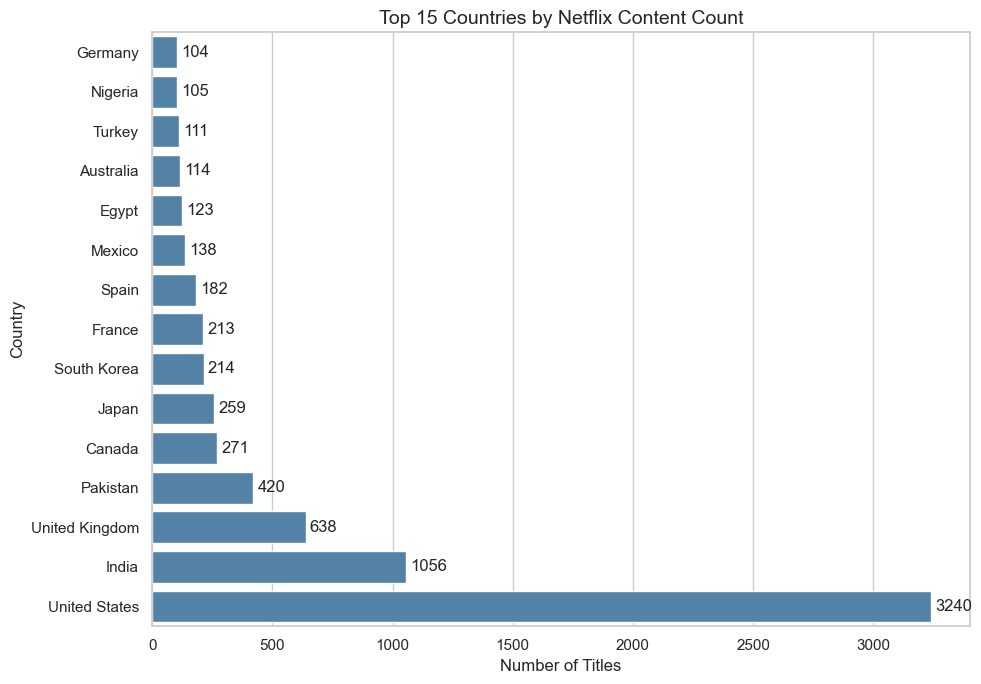

In [12]:
# Select the top 15 countries
top_15_countries = (
    country_distribution.head(15)
    .sort_values('Content Count', ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    data=top_15_countries,
    x='Content Count',
    y='Country',
    color='steelblue'
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.0f')

plt.title('Top 15 Countries by Netflix Content Count', fontsize=14)
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## Country Distribution by Content Type

This section compares the distribution of Movies and TV Shows across countries.

The analysis identifies the content type composition of each country's contribution to the Netflix catalog.

In [13]:
# Calculate content distribution by country and type
country_content_type = (
    df_country
    .groupby(['country', 'type'])
    .size()
    .unstack(fill_value=0)
)

# Calculate total content per country
country_content_type['Total'] = (
    country_content_type['Movie'] +
    country_content_type['TV Show']
)

# Sort countries by total content count
country_content_type = country_content_type.sort_values(
    'Total',
    ascending=False
)

# Display the top 15 countries
display(country_content_type.head(15))

type,Movie,TV Show,Total
country,,,
United States,2395,845,3240
India,975,81,1056
United Kingdom,387,251,638
Pakistan,71,349,420
Canada,187,84,271
Japan,87,172,259
South Korea,49,165,214
France,148,65,213
Spain,129,53,182


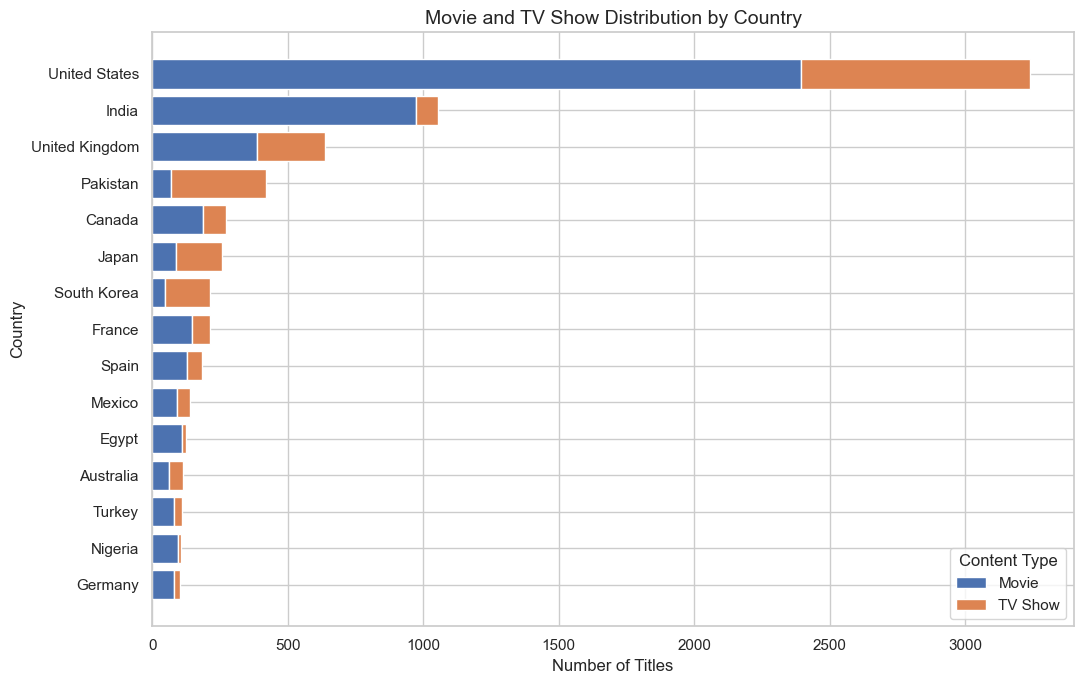

In [14]:
# Select the top 15 countries
top_15_content_type = (
    country_content_type.head(15)
    .sort_values('Total', ascending=True)
)

# Create stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_15_content_type.index,
    top_15_content_type['Movie'],
    label='Movie'
)

ax.barh(
    top_15_content_type.index,
    top_15_content_type['TV Show'],
    left=top_15_content_type['Movie'],
    label='TV Show'
)

ax.set_title('Movie and TV Show Distribution by Country', fontsize=14)
ax.set_xlabel('Number of Titles')
ax.set_ylabel('Country')
ax.legend(title='Content Type')

plt.tight_layout()
plt.show()

### Content Type Proportion by Country

This analysis compares the percentage composition of Movies and TV Shows across the top 15 countries.

A 100% stacked bar chart is used to examine differences in content type composition independently of each country's total content count.

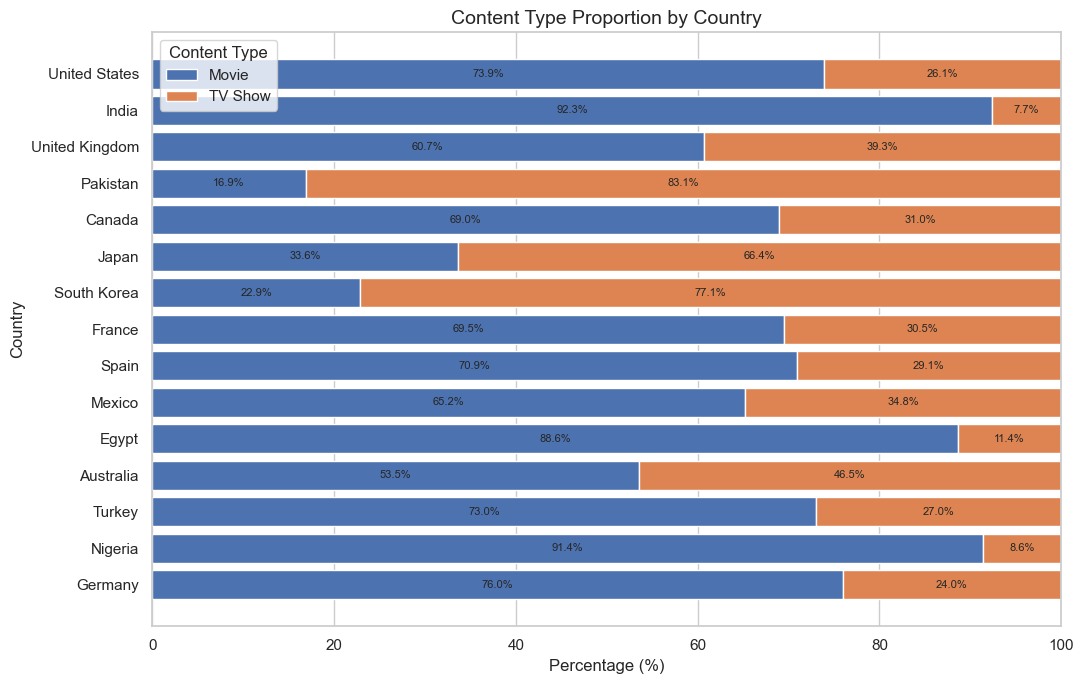

In [15]:
# Calculate content type percentages by country
country_content_percentage = (
    country_content_type[['Movie', 'TV Show']]
    .div(country_content_type['Total'], axis=0)
    * 100
)

# Select the top 15 countries
top_15_content_percentage = country_content_percentage.loc[
    top_15_content_type.index
]

# Create 100% stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars_movie = ax.barh(
    top_15_content_percentage.index,
    top_15_content_percentage['Movie'],
    label='Movie'
)

bars_tv = ax.barh(
    top_15_content_percentage.index,
    top_15_content_percentage['TV Show'],
    left=top_15_content_percentage['Movie'],
    label='TV Show'
)

# Add percentage labels
ax.bar_label(
    bars_movie,
    labels=[f'{v:.1f}%' for v in top_15_content_percentage['Movie']],
    label_type='center',
    fontsize=8
)

ax.bar_label(
    bars_tv,
    labels=[f'{v:.1f}%' for v in top_15_content_percentage['TV Show']],
    label_type='center',
    fontsize=8
)

ax.set_title('Content Type Proportion by Country', fontsize=14)
ax.set_xlabel('Percentage (%)')
ax.set_ylabel('Country')
ax.set_xlim(0, 100)
ax.legend(title='Content Type')

plt.tight_layout()
plt.show()

## Key Findings and Business Insights


### Key Findings

The country-wise analysis reveals a geographically concentrated distribution of Netflix titles, with notable differences in content type composition across countries.

The analysis reveals the following findings:

1. **United States Dominance:** The United States ranks first with 3,240 titles, accounting for 38.12% of all records with available country information. This is more than three times the number of titles attributed to India (1,056 titles).

2. **High Geographic Concentration:** The top five countries (United States, India, United Kingdom, Pakistan, and Canada) collectively account for approximately 66.18% of records with available country information.

3. **Movie-Dominated Catalogs:** India has a particularly high Movie proportion at 92.3%, followed by the United States at 73.9% and France at approximately 69.5%.

4. **Higher TV Show Representation:** Pakistan has the highest TV Show proportion among the top 15 countries at 83.1%, followed by South Korea at 77.1% and Japan at 66.4%.

5. **Differences in Content Type Composition:** The balance between Movies and TV Shows varies across countries. While Movies account for a larger proportion in most of the top 15 countries, selected countries show a stronger representation of TV Shows.

### Business Insights

The country-wise distribution indicates that Netflix's catalog in this dataset is concentrated in a relatively small number of countries, with the United States representing the largest share. The top five countries account for approximately two-thirds of all records with available country information. This highlights the importance of understanding the geographical composition of the catalog and examining content representation beyond the leading countries.

The differences in Movie and TV Show proportions across countries also demonstrate variations in catalog composition across geographical markets. India has a strongly Movie-oriented representation, whereas Pakistan, South Korea, and Japan have higher proportions of TV Shows. These patterns provide a basis for further evaluation of the content portfolio across countries.

Further analysis incorporating viewership, audience engagement, acquisition costs, and regional performance would be necessary before making specific content investment, market expansion, or audience-targeting decisions.

### Analysis Limitations

This analysis is based on country information available in the Netflix metadata dataset. A total of 287 records (3.27%) have missing country information and are excluded from country-wise calculations. Therefore, the results represent only records with available country information.

The findings describe catalog representation and content type composition, not audience preferences, viewership, revenue, or actual market performance.